# PPL: the expensive depth-pruning criterion, checked against the cheap one

Part of plan.md step 2.1 (depth pruning) -- 2407.14679's other layer-importance
criterion, alongside `03_importance_scores.ipynb`'s Block Importance (BI).
Purely observational, like that notebook: no layer has been pruned here
either.

**Why a separate notebook from `03_importance_scores.ipynb`.** BI, heads,
and experts are all cheap (one forward pass) and share one collection run;
PPL is fundamentally different in cost -- `num_layers + 1` = 49 full forward
passes per calibration sample, since the model actually has to run without
each candidate layer to know what removing it costs. That expense is the
entire reason BI exists as a proxy for it, so this notebook's real job is a
single question: **does the cheap proxy actually predict the expensive
ground truth?** This notebook loads BI's saved scores from `03`'s run
alongside PPL's own to answer that directly, rather than duplicating BI's
collection or forcing an unrelated question into that notebook.

`bonsai.importance.depth.ppl_importance` does the real work (skip each
layer via `skip_layer`, measure the mean cross-entropy loss delta); the
actual GPU orchestration lives in a throwaway script, same convention as
`03`'s own collection run. This notebook loads the saved tensors and
visualizes them.

In [1]:
import torch

BI_RUN_DIR = "../runs/20260919T150941Z-ff00be-importance-scores"
PPL_RUN_DIR = "../runs/20260919T160648Z-14fb77-ppl-depth-scores"
bi_data = torch.load(f"{BI_RUN_DIR}/importance-scores.pt", weights_only=True)
ppl_data = torch.load(f"{PPL_RUN_DIR}/ppl-scores.pt", weights_only=True)

depth_scores = bi_data["depth_scores"]  # Block Importance, from 03_importance_scores.ipynb
ppl_scores = ppl_data["ppl_scores"]

print(
    f"BI:  {bi_data['num_samples']} calibration samples, mean length {bi_data['mean_length']:.0f} tokens"
)
print(
    f"PPL: {ppl_data['num_samples']} calibration samples, mean length {ppl_data['mean_length']:.0f} tokens "
    "(fewer -- PPL costs num_layers + 1 forward passes per sample, not one)"
)
print()
print(
    f"depth_scores (BI) {tuple(depth_scores.shape)}  min={depth_scores.min():.4f} max={depth_scores.max():.4f}"
)
print(
    f"ppl_scores         {tuple(ppl_scores.shape)}  min={ppl_scores.min():.4f} max={ppl_scores.max():.4f}"
)

BI:  48 calibration samples, mean length 177 tokens
PPL: 16 calibration samples, mean length 192 tokens (fewer -- PPL costs num_layers + 1 forward passes per sample, not one)

depth_scores (BI) (48,)  min=0.0111 max=0.4881
ppl_scores         (48,)  min=-0.0003 max=1.9914


## PPL delta per layer

2407.14679's criterion: remove one layer at a time and measure the real
held-out perplexity cost. A bigger increase in loss means the layer matters
more; a delta near zero means the model barely notices it's gone.

#1 most critical by PPL: layer 0 (delta 1.9914 nats)
#2 most critical by PPL: layer 47 (delta 0.6022 nats)
#3 most critical by PPL: layer 1 (delta 0.4224 nats)


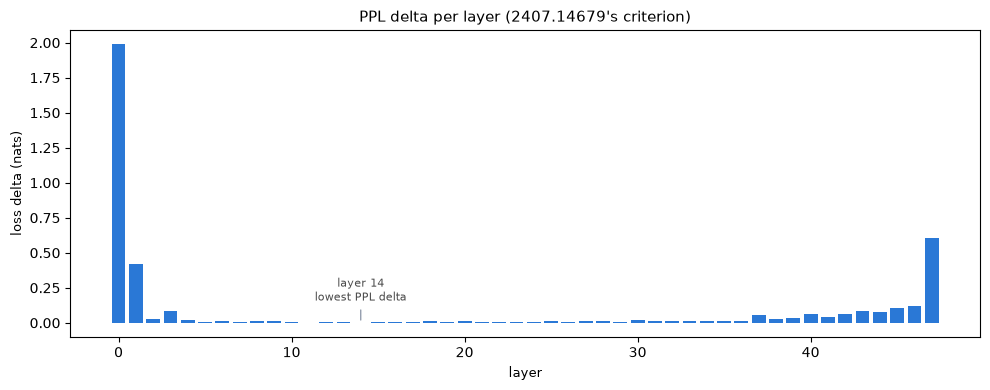

In [2]:
from bonsai.importance.viz import plot_layer_importance

fig = plot_layer_importance(
    ppl_scores,
    title="PPL delta per layer (2407.14679's criterion)",
    ylabel="loss delta (nats)",
    annotation_label="lowest PPL delta",
)
fig.savefig(f"{PPL_RUN_DIR}/ppl_bar.png", dpi=150)
fig.savefig(f"{PPL_RUN_DIR}/ppl_bar.pdf")

top3 = torch.topk(ppl_scores, 3)
for rank, (score, layer) in enumerate(
    zip(top3.values.tolist(), top3.indices.tolist(), strict=True), start=1
):
    print(f"#{rank} most critical by PPL: layer {layer} (delta {score:.4f} nats)")

## Does the cheap proxy (BI) actually predict the expensive one (PPL)?

The question that matters once two depth-scoring criteria exist: can BI be
trusted in PPL's place for cheaper, faster iteration later in Phase 2, or
does it diverge enough that the expensive version is worth paying for?

Pearson r between BI and PPL delta: 0.908
BI's top 3 layers:  [0, 1, 47]
PPL's top 3 layers: [0, 1, 47]
agreement: 3/3 layers match


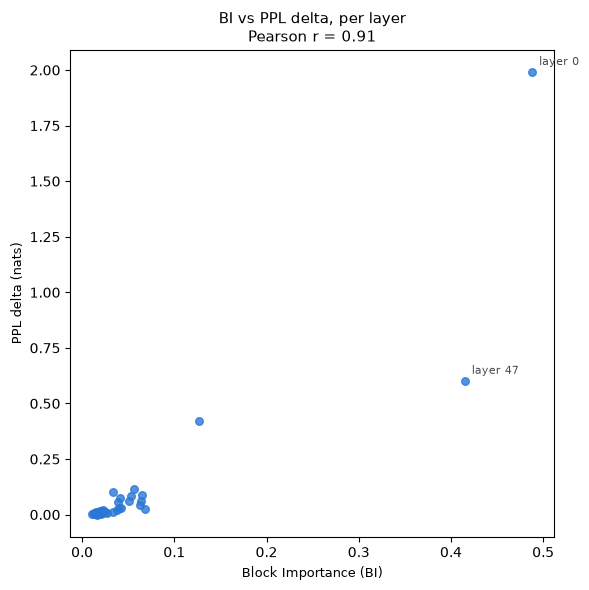

In [3]:
from bonsai.importance.viz import plot_metric_agreement

fig = plot_metric_agreement(
    depth_scores,
    ppl_scores,
    x_label="Block Importance (BI)",
    y_label="PPL delta (nats)",
    title="BI vs PPL delta, per layer",
)
fig.savefig(f"{PPL_RUN_DIR}/bi_vs_ppl.png", dpi=150)
fig.savefig(f"{PPL_RUN_DIR}/bi_vs_ppl.pdf")

correlation = torch.corrcoef(torch.stack([depth_scores, ppl_scores]))[0, 1]
print(f"Pearson r between BI and PPL delta: {correlation:.3f}")

bi_top3 = set(torch.topk(depth_scores, 3).indices.tolist())
ppl_top3 = set(torch.topk(ppl_scores, 3).indices.tolist())
print(f"BI's top 3 layers:  {sorted(bi_top3)}")
print(f"PPL's top 3 layers: {sorted(ppl_top3)}")
print(f"agreement: {len(bi_top3 & ppl_top3)}/3 layers match")

## Summary: the expensive method confirms the cheap one -- almost exactly

BI costs one forward pass; PPL costs 49. If they disagreed, PPL would be
the one to trust and BI would be dead weight for future work. They don't:

- **Pearson r = 0.91** across all 48 layers.
- Both methods pick the **exact same top 3 layers** -- 0, 47, and 1 --
  though PPL ranks them in a slightly different order of magnitude than BI
  does (PPL's layer-0 spike is far more extreme relative to the rest than
  BI's is).
- Both agree the middle third of the model (roughly layers 8-37) is the
  redundant part -- see `03_importance_scores.ipynb`'s per-layer summary
  chart, where BI and PPL track each other closely everywhere heads/experts
  don't.

**What this means for Phase 2:** BI can be trusted as a cheap stand-in for
PPL when iterating on depth-pruning candidates -- reserving PPL's real cost
for confirming a final choice rather than for every candidate along the
way. Nothing has been pruned yet; the actual depth-pruning criterion 2.1
will use (PPL/BI, or the downstream-task-based criterion still open in
plan.md) is still a decision for that step, not this one.